# RoadSafe Chicago | Partie 08 : Analyse spatiale et dashboard
**Données** : 112 056 accidents enregistrés en 2024 (`data/processed/crashes_2024.parquet`)
**Problématique** : *Comment évoluent la fréquence et la gravité des accidents routiers à Chicago, et quels facteurs sont associés à leur gravité ?*

---

### Objectif

Les parties précédentes ont répondu aux questions **« Quand ? »** et **« Dans quel contexte ? »**. Cette partie traite l'axe **« Où ? »** : comment les accidents, et surtout les accidents graves, se répartissent-ils dans la ville ?

Elle prépare ensuite les tables qui alimentent le **dashboard décisionnel**, afin de restituer l'ensemble de l'étude sous une forme exploitable par un acteur public.

### Sommaire

1. Densité des accidents sur le territoire
2. Taux de gravité par zone
3. Localisation des accidents graves impliquant des piétons
4. Classement des secteurs de police : volume ou gravité ?
5. Carte interactive des accidents graves
6. Export de la table pour le dashboard Streamlit

### Précautions de lecture

- Seuls les accidents **correctement géolocalisés** sont cartographiés (flag `geo_valid`, partie 03), soit environ 99 % du total.
- Une zone qui concentre beaucoup d'accidents n'est pas forcément **plus dangereuse** : elle est souvent simplement **plus fréquentée**. Sans données de trafic, on parle de concentration d'accidents, pas de risque.
- Les taux de gravité ne sont calculés que sur des zones d'au moins 100 accidents, pour éviter qu'un petit secteur n'apparaisse extrême par simple effet du hasard.

## Librairies 

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path
import folium
from folium.plugins import HeatMap


sns.set_theme(style="white")
FIG_DIR = Path("../reports/figures")
ANALYTICS_DIR = Path("../data/analytics")
FIG_DIR.mkdir(parents=True, exist_ok=True)
ANALYTICS_DIR.mkdir(parents=True, exist_ok=True)

In [2]:
df = pd.read_parquet("../data/processed/crashes_2024.parquet")
geo = df[df["geo_valid"]].copy()

geo.head()

,crash_record_id,crash_date,posted_speed_limit,traffic_control_device,device_condition,weather_condition,lighting_condition,first_crash_type,trafficway_type,alignment,...,delay_valid,injury_info_available,is_injury,is_fatal,is_severe,is_weekend,time_slot,season,is_dark,speed_class
0,5082d6e9f9c5c96660e7ec7fd416549e50d3130af3fc5c...,2024-06-27 13:45:00,10,NO CONTROLS,NO CONTROLS,CLEAR,DAYLIGHT,PARKED MOTOR VEHICLE,PARKING LOT,STRAIGHT AND LEVEL,...,True,True,False,False,False,False,Journée (10-15h),Été,False,≤20
1,fd34aa4f12f00106b32134531fc6e805590dbe89fef502...,2024-06-22 18:07:00,30,NO CONTROLS,NO CONTROLS,CLEAR,DAYLIGHT,PARKED MOTOR VEHICLE,NOT DIVIDED,STRAIGHT AND LEVEL,...,True,True,False,False,False,True,Soir (16-19h),Été,False,25-30
2,f0a652bf48a8c08c8a26cc981e39ed757cd41f8a771761...,2024-06-23 08:41:00,10,NO CONTROLS,NO CONTROLS,CLEAR,DAYLIGHT,REAR TO REAR,PARKING LOT,STRAIGHT AND LEVEL,...,True,True,False,False,False,True,Matin (6-9h),Été,False,≤20
3,973cda531480f4006c44691e5cc8931b9fd9d719a21264...,2024-06-19 07:35:00,30,NO CONTROLS,NO CONTROLS,CLEAR,DAYLIGHT,TURNING,T-INTERSECTION,STRAIGHT AND LEVEL,...,True,True,False,False,False,False,Matin (6-9h),Été,False,25-30
4,e66fd58b2afc22ec6aa176f149d17467d49f7ae1c83910...,2024-07-07 20:47:00,30,NO CONTROLS,NO CONTROLS,CLEAR,"DARKNESS, LIGHTED ROAD",PARKED MOTOR VEHICLE,OTHER,STRAIGHT AND LEVEL,...,True,True,True,False,False,True,Nuit (20-23h),Été,True,25-30


In [3]:

# À la latitude de Chicago, un degré de longitude est plus court qu'un degré de latitude.
# Ce ratio évite que la carte apparaisse écrasée.
ASPECT = 1 / np.cos(np.radians(41.85))

def save_fig(name):
    plt.tight_layout()
    plt.savefig(FIG_DIR / f"{name}.png", dpi=150, bbox_inches="tight")
    plt.show()

def wilson(k, n, z=1.96):
    p = k / n
    denom = 1 + z**2 / n
    centre = (p + z**2 / (2 * n)) / denom
    marge = z * np.sqrt(p * (1 - p) / n + z**2 / (4 * n**2)) / denom
    return centre - marge, centre + marge

print(f"Accidents géolocalisés : {len(geo):,} / {len(df):,}".replace(",", " "))

Accidents géolocalisés : 110 860 / 112 056


## 1. Densité des accidents sur le territoire

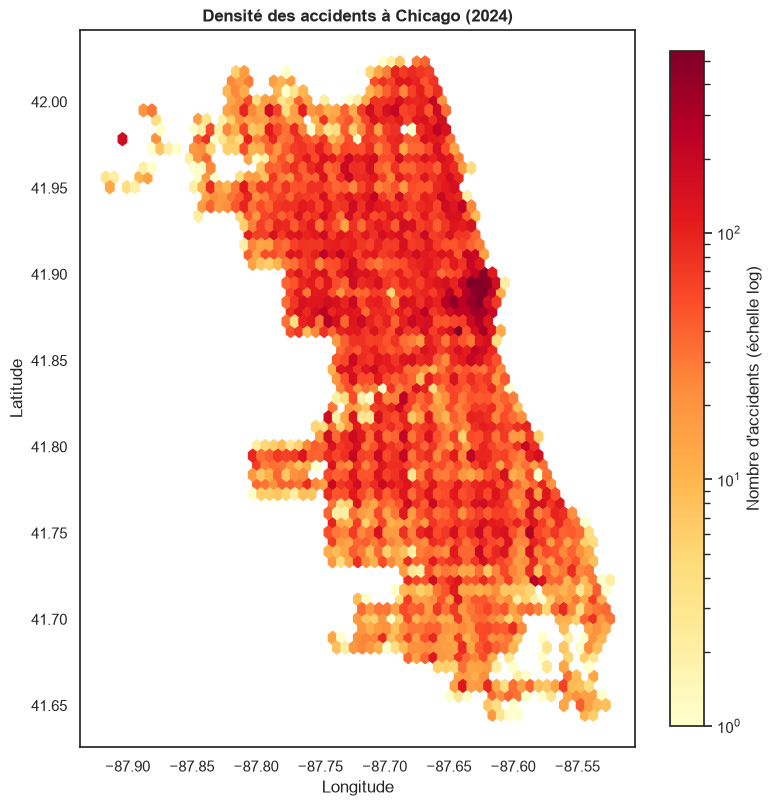

In [4]:
# Densité des accidents à Chicago

fig, ax = plt.subplots(figsize=(8, 10))
hb = ax.hexbin(geo["longitude"], geo["latitude"], gridsize=60, cmap="YlOrRd", mincnt=1, bins="log")
fig.colorbar(hb, ax=ax, label="Nombre d'accidents (échelle log)", shrink=0.7)
ax.set_aspect(ASPECT)
ax.set_title("Densité des accidents à Chicago (2024)", fontweight="bold")
ax.set_xlabel("Longitude"); ax.set_ylabel("Latitude")
save_fig("08_1_densite_accidents")

**Analyse.** Les accidents se concentrent nettement dans le centre (Loop et Near North Side), où certains hexagones dépassent plusieurs centaines d'accidents : la petite zone du Loop et de ses abords regroupe à elle seule environ 8 % des accidents de la ville. Le quadrillage des grandes artères se lit sur toute la ville. Le point dense isolé au nord ouest correspond à l'aéroport O'Hare. Ces concentrations reflètent d'abord l'intensité du trafic.

## 2. Taux de gravité par zone

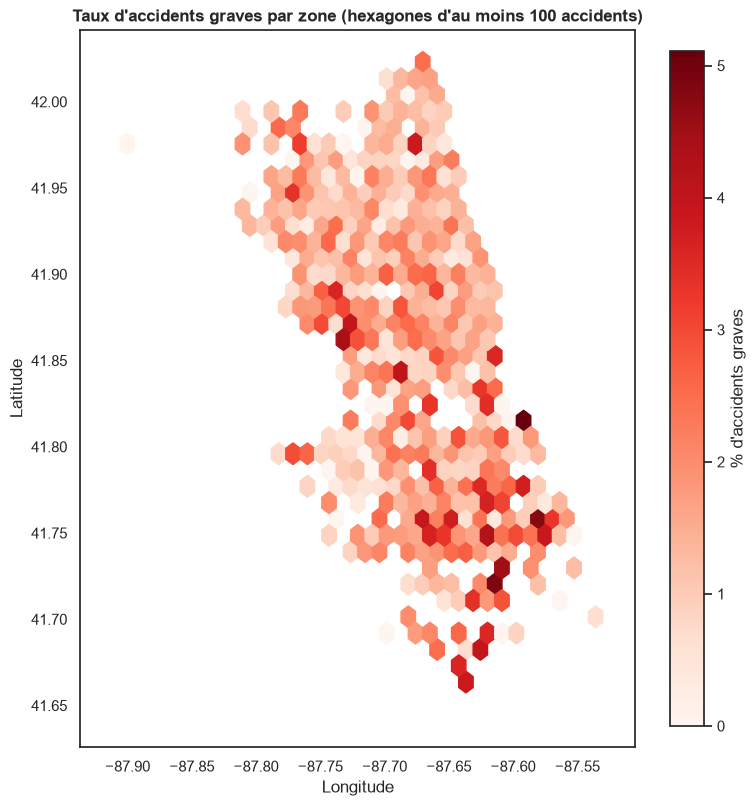

In [5]:
# Visualisation du taux d'accidents graves par zone (hexagones d'au moins 100 accidents)

g = geo.dropna(subset=["is_severe"])

fig, ax = plt.subplots(figsize=(8, 10))
hb = ax.hexbin(g["longitude"], g["latitude"], C=g["is_severe"].astype(float) * 100,
               reduce_C_function=np.mean, gridsize=35, cmap="Reds", mincnt=100)
fig.colorbar(hb, ax=ax, label="% d'accidents graves", shrink=0.7)
ax.set_aspect(ASPECT)
ax.set_title("Taux d'accidents graves par zone (hexagones d'au moins 100 accidents)", fontweight="bold")
ax.set_xlabel("Longitude"); ax.set_ylabel("Latitude")
save_fig("08_2_taux_gravite_zone")

**Analyse.** La carte de la gravité est très différente de celle du volume. Le centre, qui concentre le plus d'accidents, présente des taux plutôt faibles (1,40 % dans le Loop et ses abords, contre 1,58 % pour le reste de la ville). Les taux les plus élevés se situent dans le South Side (entre 41,70 et 41,80 de latitude) et dans le West Side (autour de -87,73 de longitude). Des voies plus rapides et moins congestionnées peuvent expliquer une partie de ces écarts ; sans données de trafic, il s'agit de concentrations de gravité et non de mesures de risque.

## 3. Accidents graves impliquant un piéton

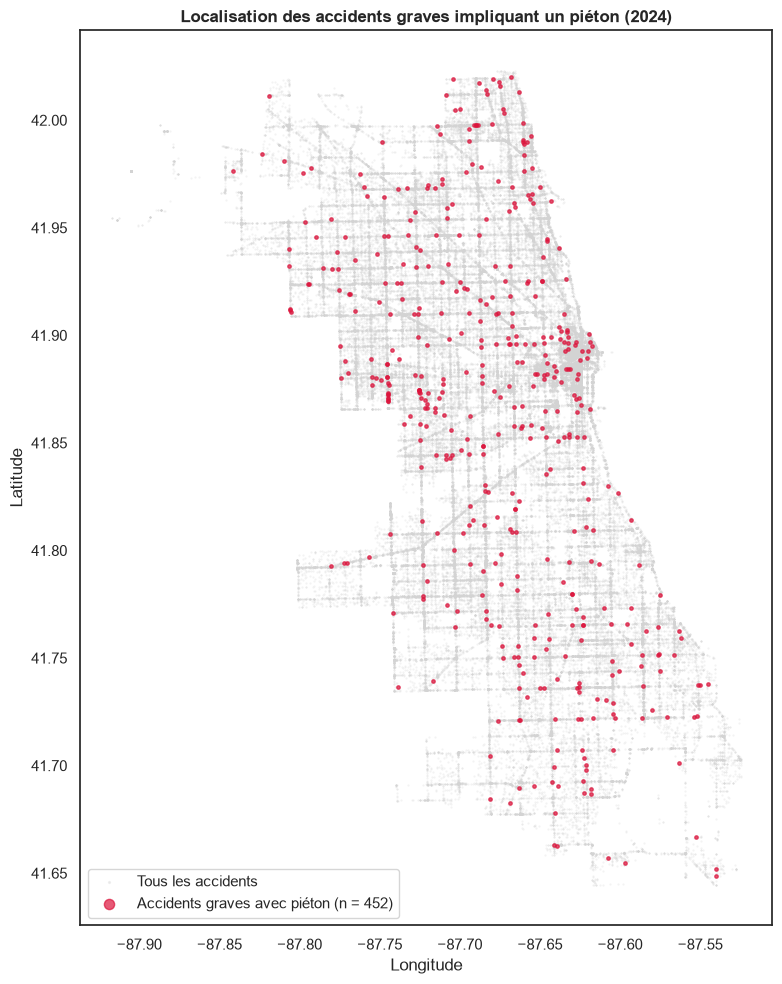

In [6]:
# Localisation des accidents graves impliquant un piéton

pietons_graves = geo[(geo["first_crash_type"] == "PEDESTRIAN") & (geo["is_severe"].fillna(False))]

fig, ax = plt.subplots(figsize=(8, 10))
ax.scatter(geo["longitude"], geo["latitude"], s=0.2, color="lightgray", alpha=0.3, label="Tous les accidents")
ax.scatter(pietons_graves["longitude"], pietons_graves["latitude"], s=6, color="crimson",
           alpha=0.7, label=f"Accidents graves avec piéton (n = {len(pietons_graves)})")
ax.set_aspect(ASPECT)
ax.set_title("Localisation des accidents graves impliquant un piéton (2024)", fontweight="bold")
ax.set_xlabel("Longitude"); ax.set_ylabel("Latitude")
ax.legend(loc="lower left", markerscale=3)
save_fig("08_3_pietons_graves")

**Analyse.** 452 accidents graves impliquent un piéton. Ils sont dispersés dans toute la ville, avec un regroupement visible dans le centre et le long de certaines artères du West Side et du South Side. Le Loop et ses abords n'en concentrent que 7,5 %, une part proche de leur poids dans l'ensemble des accidents : la sécurité des piétons est un enjeu à l'échelle de toute la ville, pas seulement du centre.

## 4. Secteurs de police : volume ou gravité ?

In [7]:
# Les secteurs de la ville avec le plus d'accidents graves

beats = (df.dropna(subset=["is_severe"])
           .groupby("beat_of_occurrence")["is_severe"]
           .agg(n="count", k="sum").astype(float))
beats = beats[beats["n"] >= 100].copy()
beats["taux_%"] = beats["k"] / beats["n"] * 100
bas, haut = wilson(beats["k"], beats["n"])
beats["ic_bas"], beats["ic_haut"] = bas * 100, haut * 100

top_volume = beats.nlargest(10, "n").index
top_taux = beats.nlargest(10, "taux_%").index
print("Secteurs à la fois dans le top 10 volume et le top 10 gravité :", set(top_volume) & set(top_taux) or "aucun")

Secteurs à la fois dans le top 10 volume et le top 10 gravité : aucun


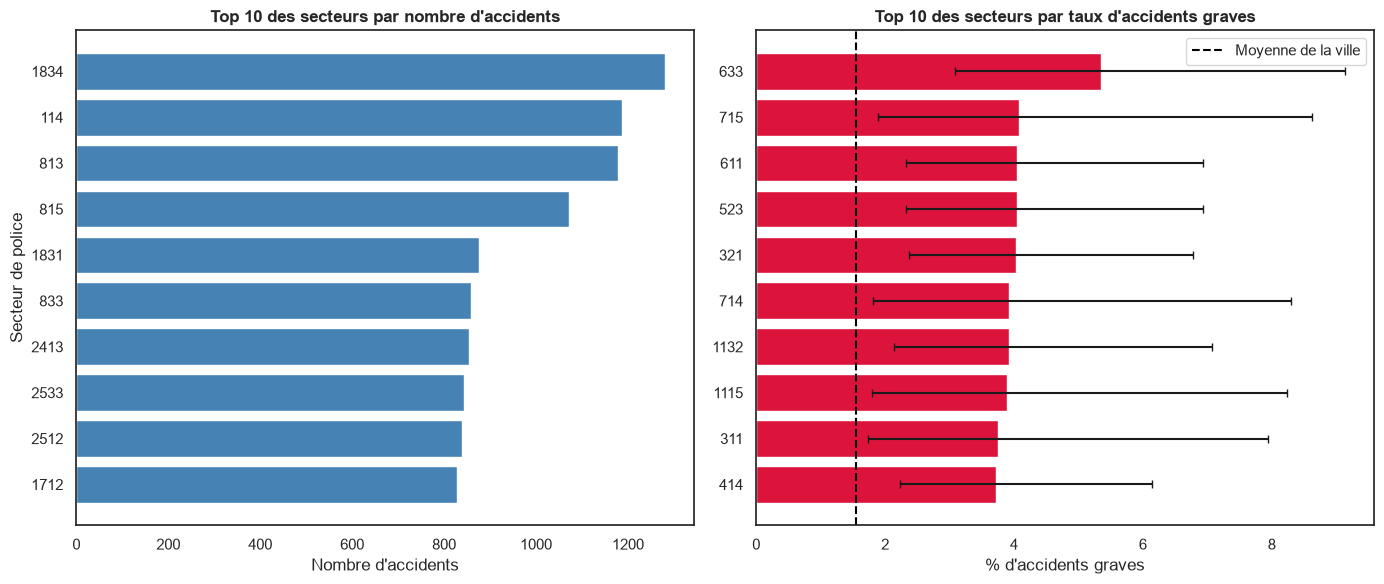

In [8]:
# Visualisation des secteurs de police avec le plus d'accidents et le plus d'accidents graves

fig, axes = plt.subplots(1, 2, figsize=(14, 6))

v = beats.loc[top_volume].sort_values("n")
axes[0].barh(v.index.astype(str), v["n"], color="steelblue")
axes[0].set_title("Top 10 des secteurs par nombre d'accidents", fontweight="bold")
axes[0].set_xlabel("Nombre d'accidents"); axes[0].set_ylabel("Secteur de police")

t = beats.loc[top_taux].sort_values("taux_%")
axes[1].barh(t.index.astype(str), t["taux_%"],
             xerr=[t["taux_%"] - t["ic_bas"], t["ic_haut"] - t["taux_%"]], color="crimson", capsize=3)
axes[1].axvline(df["is_severe"].mean() * 100, color="black", linestyle="--", label="Moyenne de la ville")
axes[1].set_title("Top 10 des secteurs par taux d'accidents graves", fontweight="bold")
axes[1].set_xlabel("% d'accidents graves"); axes[1].legend()
save_fig("08_4_secteurs_volume_vs_gravite")

**Analyse.** Aucun secteur n'apparaît à la fois dans le top 10 en volume et dans le top 10 en gravité. Les secteurs les plus accidentogènes (1834, 114, 813, avec plus de 1 100 accidents chacun) ont des taux de gravité compris entre 0,5 et 1,9 %, proches de la moyenne ou en dessous. À l'inverse, les secteurs les plus graves (633, 715, 523, 611, entre 4 et 5,4 %) comptent seulement 150 à 380 accidents ; ils appartiennent aux districts 3 à 7 et 11, au sud et à l'ouest de la ville. Leurs intervalles de confiance sont larges : ce classement désigne des secteurs à surveiller plutôt qu'un palmarès définitif. Une politique de prévention fondée uniquement sur le volume passerait à côté des zones où les accidents sont les plus graves.

## 5. Carte interactive des accidents graves

In [9]:



graves = geo[geo["is_severe"].fillna(False)]

carte = folium.Map(location=[41.85, -87.68], zoom_start=11, tiles="OpenStreetMap")
HeatMap(graves[["latitude", "longitude"]].values.tolist(), radius=9, blur=12,
        name="Accidents graves").add_to(carte)
folium.LayerControl().add_to(carte)

carte.save(FIG_DIR / "08_5_carte_accidents_graves.html")
carte

**Analyse.** La carte interactive, enregistrée dans `reports/figures/08_5_carte_accidents_graves.html`, permet de zoomer jusqu'à l'échelle de l'intersection pour repérer les carrefours où les accidents graves se répètent.

## 6. Export de la table pour le dashboard

In [10]:
# Racine du projet : on remonte jusqu'au dossier qui contient Notebooks/  pour pouvoir retrouver le fichier de données nettoyées de la partie 03
ici = Path.cwd().resolve()
ROOT = next((p for p in [ici, *ici.parents] if (p / "Notebooks").exists() or (p / ".venv").exists()), ici)
print("Racine du projet :", ROOT.name)

# Source : données nettoyées de la partie 03
source = next((p for p in [ROOT / "data" / "processed" / "crashes_2024.parquet",
                           ROOT / "Data" / "processed" / "crashes_2024.parquet"] if p.exists()), None)
print("Source :", source.relative_to(ROOT))

df = pd.read_parquet(source)

cols_dashboard = [
    "crash_record_id", "crash_date", "crash_month", "crash_hour", "crash_day_of_week",
    "is_weekend", "time_slot", "season",
    "latitude", "longitude", "geo_valid", "beat_of_occurrence",
    "weather_condition", "lighting_condition", "roadway_surface_cond",
    "posted_speed_limit", "speed_class", "speed_valid",
    "first_crash_type", "prim_contributory_cause",
    "injuries_total", "injuries_fatal", "injuries_incapacitating",
    "is_injury", "is_severe", "is_fatal",
]
manquantes = [c for c in cols_dashboard if c not in df.columns]
print("Colonnes manquantes :", manquantes or "aucune")

sortie = ROOT / "data" / "analytics" / "fact_crashes_2024.parquet"
sortie.parent.mkdir(parents=True, exist_ok=True)
df[[c for c in cols_dashboard if c in df.columns]].to_parquet(sortie, index=False)

print("Fichier écrit :", sortie.relative_to(ROOT), "| existe :", sortie.exists())

Racine du projet : Accident-de-la-route-Chicago
Source : data/processed/crashes_2024.parquet
Colonnes manquantes : aucune


Fichier écrit : data/analytics/fact_crashes_2024.parquet | existe : True


**Analyse.** La table de faits ne garde que les 26 colonnes utiles au dashboard Streamlit (`Acc_Dashboard_Streamlit.py`), ce qui allège le fichier et accélère son chargement.

## Bilan

- **Le volume se concentre au centre**, là où le trafic est le plus dense, mais **la gravité se concentre au sud et à l'ouest**.
- Les secteurs les plus accidentogènes et les plus graves sont **différents** : les deux indicateurs doivent être suivis ensemble.
- Les accidents graves impliquant des piétons sont répartis dans toute la ville.
- Sans données de trafic par zone, ces cartes décrivent où se produisent les accidents graves, pas où le risque individuel est le plus élevé.